# Demo of removing jumps in hyperspectral signatures from multiple sensors

## You will need "spectral", a hyperspectral toolbox and appf_toolbox (https://github.com/Harwis/appf_toolbox)

In [17]:
import sys
sys.path.append('/home/huajianliu/appn-tpa/huajian/projects/appf_toolbox')
import numpy as np
import appf_toolbox.hyper_processing.pre_processing as pp



## Have a look at the remove_jump function

In [18]:
print(pp.remove_jumps.__doc__)


Remove the jumps in a spectral signature.

:param spec_sig: the spectral signature need to be fixed; 1D ndarray format

:param ind_jumps: the indices of jumps; must be a list; the indices starts from 0; default is []; [650, 1480] for
       FieldSpec data; [398] for hyp images of vnir + swir

:param  num_points: the number points to fit a line on the left-side of the jumps

:param flag_auto_detect_jumps: the flag to determine if use auto detection of the jumps or not; default is False

:param t_der: the threshold of the second derivative; if a value > t_der, then it is a jump; only used when
       flag_auto_detect-jumps == True; default is 0.004 for FieldSpec data; recommend 0.01 for imaging data.

:param r_win: the radius of the window to distinguish jumps and randoms noises;
       only used when flag_auto_detect_jumps == True; default is 15.

:param flag_plot_result: the flag to indicate if show the results in a figure or not; default is False

:return: If ind_jumps is not empty, 

## The demo data directory and name

In [19]:
data_path = 'demo_data'
data_name = 'FieldSpec_demo_data.npy'
data_id = 6 # The ID of the reflectance. You can change it from 0 to 9.

# Load data

In [20]:
data = np.load(data_path + '/' + data_name, allow_pickle=True)
data = data.flat[0]
ref = data['reflectance']
a_ref = ref[data_id]

# Made fake jumps at the band of 650 and 1480

In [21]:
ind_jump = [600, 1480] # Manually input the indices of jumps
a_ref[ind_jump[0] + 1:] = a_ref[ind_jump[0] + 1:] + 0.1
a_ref[ind_jump[1] + 1:] = a_ref[ind_jump[1] + 1:] - 0.05

# Remove the jumps through manual inputing the band numbers of the jumps. 

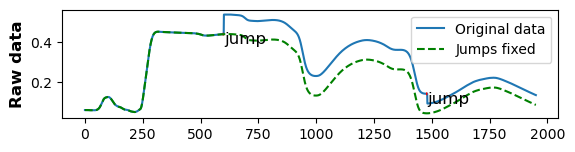

In [22]:
ref = pp.remove_jumps(a_ref, ind_jumps=ind_jump, flag_auto_detect_jumps=False, flag_plot_result=True)

In [23]:
print(ind_jump)

[600, 1480]


# It can automatically remove the jumps if you do not know where the jumps are.


Jumps found at bands  [ 600 1480]


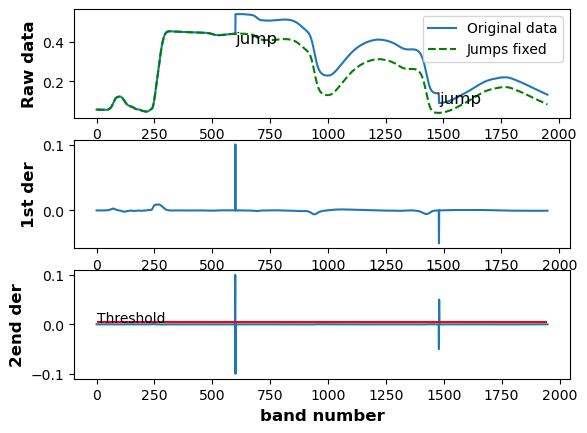

In [24]:
ref = pp.remove_jumps(a_ref, flag_auto_detect_jumps=True, flag_plot_result=True)